## **დავალებები: Linear Regression**

ამ დავალებისთვის გამოვიყენებთ ერთ-ერთი მაღაზიის მყიდველების მონაცემებს. 
ეს მაღაზია ტანსაცმელს ყიდის online, თუმცა ასევე შესაძლებელია მაღაზიაში სტილის შერჩევისთვის
კონსულტაციის მიღება და ვიზიტის ჩანიშვნა. კლიენტებს აქვთ შეხვედრა სტილისტებთან, რის შემდეგაც 
მათ შეუძლიათ მობილური აპლიკაციის ან ვებსაიტის მეშვეობით შეუკვეთონ შერჩეული ტანსაცმელი.

კომპანიას უნდა გადაწყვიტოს რაზე უფრო დაფოკუსირდეს: მობილურ აპლიკაციაზე თუ ვებსაიტზე. 
თქვენ დაგიქირავეს იმისათვის რომ დაეხმაროთ ამ გადაწყვეტილების მიღებაში.

მონაცემების ფაილი შეიცავს მომხმარებელთა ინფორმაციას:
- Email: ელ.ფოსტა
- Address: მისამართი
- Avatar: ავატარის ფერი
- Avg. Session Length: მაღაზიაში სტილის კონსულტაციების სესიების საშუალო ხანგრძლივობა
- Time on App: აპლიკაციაზე დახარჯული საშუალო დრო წუთებში
- Time on Website: ვებგვერდზე დახარჯული საშუალო დრო წუთებში
- Length of Membership: რამდენი წელია, რომ მომხმარებელი წევრია
- Yearly Amount Spent: წლიურად რა თანხა დახარჯა ამ მომხმარებელმა

### წრფივი რეგრესია
- **მონაცემების ფაილიდან წაკითხვა**
  - წაიკითხეთ მონაცემები customers.csv ფაილიდან (ფაილი მოთავსებულია: "../../datasets/ecommerce_company/customers.csv")..
  - გამოიყენეთ მეთოდები, როგორიცაა `.head()`, `.info()` და `.describe()` მონაცემთა ფორმატსა და შიგთავსზე საწყისი შთაბეჭდილების შესაქმნელად.
  - დააკვირდით, რომელი სვეტი წარმოადგენს სამიზნე ცვლადს (რომელი სვეტის პროგნოზს გააკეთებდით)
- **მონაცემების ანალიზი**
  - შექმენით თქვენი ვარაუდის მიხედვით სხვადასხვა გრაფიკები და დააკვირდით მონაცემებს
     - შეამოწმეთ ჰიპოთეზები:
     - More Time on App, more money spent
     - More Time on Website, more money spent
  - ააგეთ scatter გრაფიკი: "Time on App" vs. "Length of Membership"
  - ყველაზე მეტად რომელი სვეტი კორელირებს "Yearly Amount Spent"-თან?
- **მოდელი**
  - შეარჩიეთ მახასიათებლები რომლებსაც გამოიყენებთ მოდელის გაწვრთნისას
  - "Yearly Amount Spent" არის სამიზნე სვეტი (y)
  - დაყავით მონაცემები training და testing სიმრავლეებად
  - გამოიყენეთ StandardScaler მონაცემების ნორმალისაციისათვის
  - გაწვრთენით LinearRegression მოდელი training მონაცემებზე
  - დაბეჭდეთ მოდელის კოეფიციენტები
  - ააგეთ Feature Importance გრაფიკი
  - გააკეთეთ პროგნოზი testing მონაცემებზე
  - შექმენით გრაფიკი, სადაც შეადარებთ test values vs. predicted values
  - მოახდინეთ მოდელის ევალუაცია: გამოითვალეთ ევალუაციის მეტრიკები
  - ააგეთ residuals-ის განაწილების გრაფიკი, რა დასკვნას გამოიტანდით ამ გრაფიკიდან?
  - გვაქვს თუ არა ამ მონაცემებისთვის მულტიკოლინეარობის პრობლემა?
  - რას ფიქრობთ, კომპანია უნდა დაფოკუსირდეს მობილურ აპლიკაციაზე თუ ვებსაიტზე?

In [22]:
import pandas as pd
data = pd.read_csv(r"C:\Users\amiri\OneDrive\Desktop\Projcets\Commshcool_DS\ds-course-materials\datasets\ecommerce_company\customers.csv")
data.head(2)

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933


In [29]:
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns


def define_target(df):
    df = df.drop(columns=["Email","Address"])
    X = df.drop(columns = "Yearly Amount Spent")
    y = df["Yearly Amount Spent"]
    return X,y

def split_data():
    X,y = define_target(data)
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test

def nums_cats():
    X_train, _, _, _ = split_data()
    nums = X_train.select_dtypes(include= "number").columns
    cats = X_train.select_dtypes(include= "object").columns
    return nums,cats

def preprocessing():
    nums, cats = nums_cats()
    prep = ColumnTransformer([
        ("nums",StandardScaler() ,nums),
        ("cats",OneHotEncoder(handle_unknown="ignore") ,cats),
    ])
    return prep

def pipeline(model):
    prep = preprocessing()
    pipe= Pipeline([
        ("preprocess",prep),
        ("model",model)
    ])
    return pipe

def predicting():
    X_train, X_test, y_train, y_test = split_data()
    models = {
        # "RandomForestRegressor" : RandomForestRegressor(random_state=42),
        # "GradientBoostingRegressor" : GradientBoostingRegressor(random_state=42),
        "LinearRegression" : LinearRegression()
     }
    results = None
    for model_name, model in models.items():
        mod = pipeline(model)
        y_pred_train = cross_val_predict(mod,X_train,y_train,cv=5)
        mae=  mean_absolute_error(y_train,y_pred_train)
        temp = pd.DataFrame({
                            "MAE": [mae],
                            "Model_Name": [model_name]
                        })
        results = pd.concat([results,temp])

        mod.fit(X_train,y_train)
        importance = model.coef_
        y_pred_test = mod.predict(X_test)
        mae_test = mean_absolute_error(y_test,y_pred_test)

        plt.figure(figsize=(6,4))
        sns.scatterplot(x=y_test, y=y_pred_test)
        plt.xlabel("Actual Values")
        plt.ylabel("Predicted Values")
        plt.title("Predicted vs Actual")
        plt.show()



    return results, mae_test, importance

    # LINEAR REGRESSION HAS LOWER MAE SO WE LEAVE THAT MODEL
    




C:\Users\amiri\AppData\Local\Temp\ipykernel_22772\2501749622.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats = X_train.select_dtypes(include= "object").columns


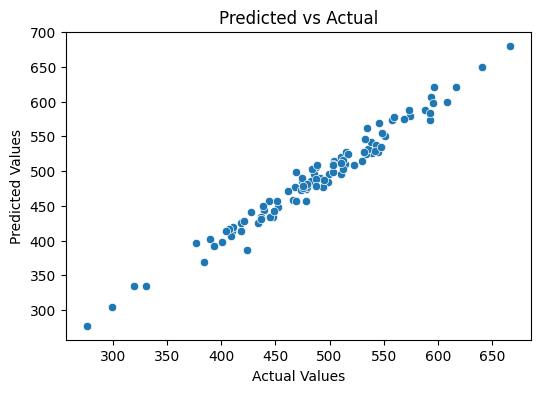

array([ 2.49615989e+01,  3.82730351e+01,  2.36061158e-01,  6.35033915e+01,
       -8.59073809e-01, -1.99887626e+00, -5.23818590e+00, -5.25079873e+00,
       -4.53071295e+00, -6.62524427e+00,  2.75692644e-02,  1.33935755e+00,
        2.34340034e+00,  5.37802167e+00,  2.79884466e+00, -4.73103379e-01,
       -3.71592963e+00, -6.27212420e+00, -6.34804746e+00,  2.81219914e+00,
       -4.47487054e+00, -6.27593749e+00,  3.65273336e+00, -6.93534004e+00,
        7.67512614e+00, -2.93391655e+00,  2.24009426e+00, -4.03630982e-01,
        4.81068922e+00, -4.47924432e+00,  5.47262875e+00, -4.43671010e+00,
       -7.66116901e+00, -1.18599232e+01,  3.30484423e+00, -9.77396558e-01,
        1.52797919e+00, -3.14207679e+00, -9.79707536e-01, -8.46206274e-01,
       -7.80936276e+00,  3.94194669e+00,  3.36499380e-01, -6.78705092e+00,
        7.32570430e+00, -4.27850798e+00,  1.49144658e+01, -1.22280880e+00,
        4.70696780e+00, -5.65591872e+00, -5.43431168e+00, -5.41758724e+00,
        2.69154727e+00, -

In [32]:
results, mae_test, importance = predicting()
importance

In [10]:
nums_cats()

C:\Users\amiri\AppData\Local\Temp\ipykernel_22772\874002088.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cats = X_train.select_dtypes(include= "object").columns


(Index(['Avg. Session Length', 'Time on App', 'Time on Website',
        'Length of Membership'],
       dtype='str'),
 Index(['Address', 'Avatar'], dtype='str'))